In [39]:
%matplotlib widget
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib
from dataclasses import dataclass

# ============================================================
# 1. STYLE & OBJECT CONFIGURATION
# ============================================================
@dataclass
class Spectrum:
    N: str                      # Nombre o Label
    X: np.ndarray               # Wavelength (nm)
    Y: np.ndarray               # Absorbance / Intensity
    wcorr: float = 0.0          # Factor de corrección de agua
    color: str = None           # Color para ploteo
    linestyle: str = None       # Estilo de línea
    
    def copy(self):
        """Devuelve una copia profunda del espectro."""
        return Spectrum(
            N=self.N, 
            X=self.X.copy(), 
            Y=self.Y.copy(), 
            wcorr=self.wcorr, 
            color=self.color,         
            linestyle=self.linestyle  
        )

poster_style = {
    "figsize": (5, 5),          
    "dpi": 200,                 
    "font_size": 10,
    "title_size": 12,
    "label_size": 12,
    "legend_size": 8,
    "line_width": 1.0,
    "font_family": "Calibri",
    "grid": True,               
    "colors": ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442"], 
    "linestyles": ["-", "--", "-.", ":"]
}

# ============================================================
# 2. CORE PLOTTING FUNCTION
# ============================================================
def PlotSpectra(
        spectra_list, mode="W", style=poster_style, offset_step=0.0,
        xmin=None, xmax=None, ymin=None, ymax=None, 
        xlabel_W="Wavelength (nm)", xlabel_E="Energy (eV)", ylabel="Absorbance",
        hide_yticks=False, save_path=None, legend_ncol=1
):
    fig, ax1 = plt.subplots(figsize=style["figsize"], dpi=style["dpi"])
    plt.rcParams.update({"font.size": style["font_size"], "font.family": style["font_family"]})
    
    default_colors = style.get("colors") or ["#000000"]
    default_linestyles = style.get("linestyles") or ["-"]
    
    for i, s in enumerate(spectra_list):
        y_offset = s.Y + (i * offset_step)
        c = getattr(s, 'color', None) or default_colors[i % len(default_colors)]
        ls = getattr(s, 'linestyle', None) or default_linestyles[i % len(default_linestyles)]

        if mode in ["W", "WE"]:
            ax1.plot(s.X, y_offset, label=s.N, linewidth=style["line_width"], color=c, linestyle=ls)
            ax1.set_xlabel(xlabel_W, fontsize=style["label_size"])
        elif mode in ["E", "EW"]:
            E_array = np.divide(1240.0, s.X, out=np.zeros_like(s.X), where=s.X != 0)
            ax1.plot(E_array, y_offset, label=s.N, linewidth=style["line_width"], color=c, linestyle=ls)
            ax1.set_xlabel(xlabel_E, fontsize=style["label_size"])

    ax1.set_ylabel(ylabel, fontsize=style["label_size"])
    
    if xmin is not None or xmax is not None: ax1.set_xlim(xmin, xmax)
    if ymin is not None or ymax is not None: ax1.set_ylim(ymin, ymax)
    if style.get("grid", False): ax1.grid(True, alpha=0.3)
    if hide_yticks: ax1.set_yticklabels([])

    if mode in ["WE", "EW"]:
        def forward(x):
            with np.errstate(divide='ignore', invalid='ignore'):
                return np.where(x == 0, np.inf, 1240.0 / x)
        def inverse(x):
            with np.errstate(divide='ignore', invalid='ignore'):
                return np.where(x == 0, np.inf, 1240.0 / x)

        if mode == "WE":
            ax2 = ax1.secondary_xaxis('top', functions=(forward, inverse))
            ax2.set_xlabel(xlabel_E, fontsize=style["label_size"])
        elif mode == "EW":
            ax2 = ax1.secondary_xaxis('top', functions=(inverse, forward))
            ax2.set_xlabel(xlabel_W, fontsize=style["label_size"])

    ax1.legend(fontsize=style["legend_size"], ncol=legend_ncol, frameon=False)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=style["dpi"], bbox_inches="tight")
    plt.show()

# --- 3. CORE PROCESSING FUNCTIONS (TRIM, BASELINE, NORMALIZE) ---

def TrimSpectrum(spectra_input, xmin=None, xmax=None):
    """Trims a single Spectrum object OR a list of them to [xmin, xmax]."""
    # Si es una lista, aplica la función a cada elemento
    if not isinstance(spectra_input, Spectrum):
        return [TrimSpectrum(s, xmin, xmax) for s in spectra_input]
        
    # Si es un objeto individual:
    s = spectra_input.copy()
    mask = np.ones_like(s.X, dtype=bool)
    if xmin is not None:
        mask &= (s.X >= xmin)
    if xmax is not None:
        mask &= (s.X <= xmax)
        
    s.X = s.X[mask]
    s.Y = s.Y[mask]
    return s

def SubtractBaseline(spectra_input, poly_order=1, anchor_windows=None):
    """Subtracts a baseline from a single Spectrum OR a list of them."""
    if not isinstance(spectra_input, Spectrum):
        return [SubtractBaseline(s, poly_order, anchor_windows) for s in spectra_input]

    s = spectra_input.copy()
    X, Y = s.X, s.Y
    if len(X) == 0:
        return s

    if poly_order == 0:
        s.Y = Y - np.min(Y)
        return s

    if anchor_windows is None:
        n_pts = max(3, int(len(X) * 0.05))
        mask = np.zeros_like(X, dtype=bool)
        mask[:n_pts] = True
        mask[-n_pts:] = True
    else:
        mask = np.zeros_like(X, dtype=bool)
        for wmin, wmax in anchor_windows:
            mask |= ((X >= wmin) & (X <= wmax))

    if np.sum(mask) > poly_order:
        coeffs = np.polyfit(X[mask], Y[mask], poly_order)
        baseline = np.polyval(coeffs, X)
        s.Y = Y - baseline
    return s

def NormalizeSpectrum(spectra_input, xmin=None, xmax=None, mode="M", subtract_min_first=True):
    """Normalizes a single Spectrum object OR a list of them within [xmin, xmax]."""
    if not isinstance(spectra_input, Spectrum):
        return [NormalizeSpectrum(s, xmin, xmax, mode, subtract_min_first) for s in spectra_input]

    s = spectra_input.copy()
    if mode is None or mode.upper() == "NONE":
        return s

    X, Y = s.X, s.Y
    mask = np.ones_like(X, dtype=bool)
    if xmin is not None:
        mask &= (X >= xmin)
    if xmax is not None:
        mask &= (X <= xmax)

    X_win, Y_win = X[mask], Y[mask]
    if len(X_win) == 0:
        return s

    if subtract_min_first:
        min_val = np.min(Y_win)
        Y = Y - min_val
        Y_win = Y_win - min_val

    mode = mode.upper()
    if mode == "M":
        factor = np.max(Y_win)
    elif mode == "I":
        factor = np.trapezoid(Y_win, X_win)
    elif mode == "V":
        factor = np.min(Y_win)
    else:
        raise ValueError("Mode must be 'M', 'I', 'V', or 'NONE'")

    if factor != 0:
        s.Y = Y / factor
    return s
# ============================================================
# 3. LOAD EXPERIMENTAL DATA INTO SPECTRUM OBJECTS
# ============================================================
txt_folders = [
    r"H:\FUBerlin\Measurements\UVvisNIR\SalomeF",
]

print("Loading Experimental Spectra...")

for txt_folder in txt_folders:
    if not os.path.exists(txt_folder):
        continue
    for file in os.listdir(txt_folder):
        if not file.lower().endswith(".csv"):
            continue
            
        path = os.path.join(txt_folder, file)
        
        try:
            df = pd.read_csv(
                path, 
                sep=";", 
                skiprows=1, 
                names=["Wavelength", "Abs"],
                decimal=","
            )
            df = df.dropna().sort_values("Wavelength").reset_index(drop=True)
            
            # Crear nombre de variable limpio basado en el archivo
            var_name = "S" + file.replace(".csv", "").replace("@", "_").replace("-", "_").replace(" ", "_")
            
            # Instanciar el objeto Spectrum y registrarlo globalmente
            globals()[var_name] = Spectrum(
                N=var_name, 
                X=df["Wavelength"].values, 
                Y=df["Abs"].values
            )
            
            print(f"Loaded successfully: {var_name}")
            
        except Exception as e:
            print(f"Could not load {file}: {e}")


Loading Experimental Spectra...
Loaded successfully: S20261106_phDADQFilling_HS64
Loaded successfully: S20261106_phDADQFilling_HS64Washed


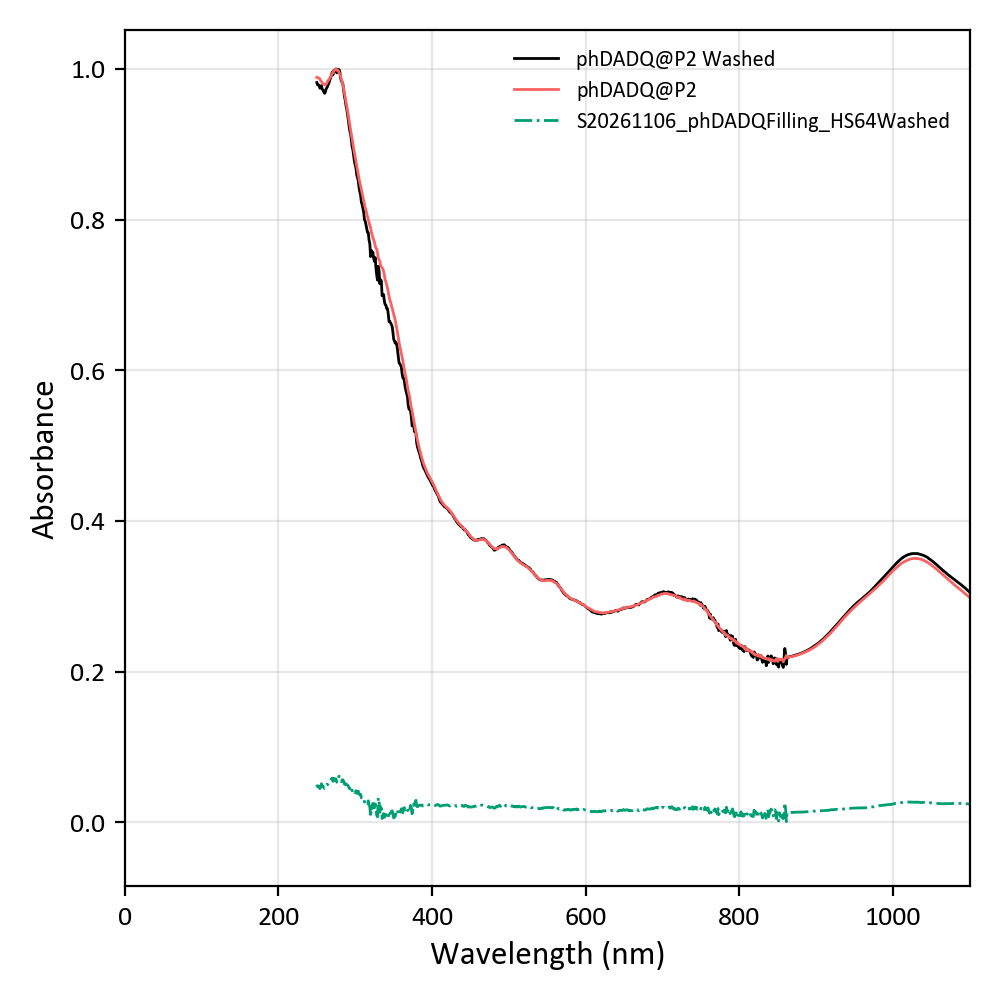

In [46]:

# ============================================================
# 4. CONFIGURATION, PIPELINE & PLOTTING
# ============================================================

# 1. Configuración usando las variables globales creadas en el paso 3
# Asegúrate de que los nombres aquí coincidan exactamente con lo que imprimió "Loaded successfully:"

spectra_config = [
    # (Variable, Etiqueta, wcorr, Color, Linestyle)
    (S20261106_phDADQFilling_HS64Washed, "phDADQ@P2 Washed", 0.2, "#000000", "-"),
    (S20261106_phDADQFilling_HS64,       "phDADQ@P2",        0.2, "#fa6262", "-"),
]



# 2. Construcción segura de la lista de selección
Selection = []
for var, name, factor, col, ls in spectra_config:
    s = var.copy() # Protege la variable original de ser modificada
    s.N = name
    s.wcorr = factor
    s.color = col
    s.linestyle = ls
    Selection.append(s)



Selection = NormalizeSpectrum(Selection, xmin=0, xmax=1260, mode="M", subtract_min_first=False)
S20261106_subs = S20261106_phDADQFilling_HS64Washed.copy()
S20261106_subs.Y = S20261106_phDADQFilling_HS64Washed.Y - S20261106_phDADQFilling_HS64.Y

Selection.append(S20261106_subs)

# (Aquí puedes agregar tus funciones TrimSpectra, NormalizeSpectra, etc. sobre 'Selection' si las necesitas)

# 3. Graficar
PlotSpectra(
    spectra_list=Selection, 
    mode="W",            # Cámbialo a "WE" si también quieres ver eV arriba
    style=poster_style, 
    offset_step=0.0,
    xmin=0, xmax=1100, 
    ymin=None, ymax=None, 
    ylabel="Absorbance",
    hide_yticks=False, 
    save_path=None
)